# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** TATA IVANKA
- **Email:** ds284b6y1710@student.devacademy.id
- **ID Dicoding:** DS284B6Y1710

Sumber data: berkas Bike Sharing Dataset dari penugasan Dicoding. Periode: 1 Januari 2011–31 Desember 2012.
Referensi dataset: Fanaee-T, H. (2013). *Bike Sharing*. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894.
Atribusi publikasi pada Readme sumber: Fanaee-T, H., & Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge*. https://doi.org/10.1007/s13748-013-0040-3.


## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Selama 1 Januari 2011–31 Desember 2012, tiga jam mana yang memiliki rata-rata jumlah penyewaan tertinggi pada hari kerja dan nonkerja, untuk menentukan prioritas jadwal kesiapan layanan? Perbandingan utama menggunakan tanggal dengan 24 catatan jam lengkap.
- **Pertanyaan 2:** Berapa perubahan rata-rata jumlah penyewaan per hari pada setiap bulan tahun 2012 dibandingkan bulan yang sama pada 2011, dan bulan mana yang perlu diprioritaskan dalam perencanaan kapasitas berdasarkan besarnya permintaan dan pertumbuhannya?

| Unsur SMART | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Pola jam sibuk, dipisah menurut workingday | Perbandingan bulan yang sama pada dua tahun |
| Measurable | Mean cnt per jam dan tiga peringkat tertinggi | Mean cnt harian, selisih absolut, dan persentase YoY |
| Action-oriented | Prioritas waktu kesiapan layanan | Prioritas kapasitas berdasarkan pola bulanan |
| Relevant | Mendukung perencanaan layanan penyewaan | Mendukung perencanaan permintaan musiman |
| Time-bound | 1 Januari 2011–31 Desember 2012 | Januari–Desember 2012 dibandingkan 2011 |

`cnt` menghitung kejadian penyewaan. `workingday=0` mencakup akhir pekan dan hari libur.
Analisis bersifat deskriptif pada periode historis tersebut; data ini belum memberikan stok sepeda,
permintaan yang tidak terlayani, atau detail tiap stasiun.


## Import Semua Packages/Library yang Digunakan

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})


## Data Wrangling

### Gathering Data

#### Memuat data harian dan per jam


In [26]:
# Di repository: CSV berada di data/. Di Colab: boleh diunggah ke /content.
DATA_DIR = Path('data') if Path('data/day.csv').is_file() else Path('.')
required_files = [DATA_DIR / 'day.csv', DATA_DIR / 'hour.csv']
if not all(path.is_file() for path in required_files):
    raise FileNotFoundError('Unggah day.csv dan hour.csv ke panel Files Colab, lalu jalankan ulang.')

day_df = pd.read_csv(DATA_DIR / 'day.csv')
hour_df = pd.read_csv(DATA_DIR / 'hour.csv')

for name, frame in [('day.csv', day_df), ('hour.csv', hour_df)]:
    print(f'\n{name}: {frame.shape[0]:,} baris, {frame.shape[1]} kolom')
    display(frame.head())
    frame.info()
    display(frame.describe().round(2))

print('Periode harian:', day_df['dteday'].min(), 'sampai', day_df['dteday'].max())



day.csv: 731 baris, 16 kolom


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.0,731.00,731.00,731.0,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,366.00,2.50,0.5,6.52,0.03,3.0,0.68,1.40,0.50,0.47,0.63,0.19,848.18,3656.17,4504.35
std,211.17,1.11,0.5,3.45,0.17,2.0,0.47,0.54,0.18,0.16,0.14,0.08,686.62,1560.26,1937.21
min,1.00,1.00,0.0,1.00,0.00,0.0,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00
25%,183.50,2.00,0.0,4.00,0.00,1.0,0.00,1.00,0.34,0.34,0.52,0.13,315.50,2497.00,3152.00
50%,366.00,3.00,1.0,7.00,0.00,3.0,1.00,1.00,0.50,0.49,0.63,0.18,713.00,3662.00,4548.00
75%,548.50,3.00,1.0,10.00,0.00,5.0,1.00,2.00,0.66,0.61,0.73,0.23,1096.00,4776.50,5956.00
max,731.00,4.00,1.0,12.00,1.00,6.0,1.00,3.00,0.86,0.84,0.97,0.51,3410.00,6946.00,8714.00



hour.csv: 17,379 baris, 17 kolom


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.00,17379.00,17379.0,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00,17379.00
mean,8690.00,2.50,0.5,6.54,11.55,0.03,3.00,0.68,1.43,0.50,0.48,0.63,0.19,35.68,153.79,189.46
std,5017.03,1.11,0.5,3.44,6.91,0.17,2.01,0.47,0.64,0.19,0.17,0.19,0.12,49.31,151.36,181.39
min,1.00,1.00,0.0,1.00,0.00,0.00,0.00,0.00,1.00,0.02,0.00,0.00,0.00,0.00,0.00,1.00
25%,4345.50,2.00,0.0,4.00,6.00,0.00,1.00,0.00,1.00,0.34,0.33,0.48,0.10,4.00,34.00,40.00
50%,8690.00,3.00,1.0,7.00,12.00,0.00,3.00,1.00,1.00,0.50,0.48,0.63,0.19,17.00,115.00,142.00
75%,13034.50,3.00,1.0,10.00,18.00,0.00,5.00,1.00,2.00,0.66,0.62,0.78,0.25,48.00,220.00,281.00
max,17379.00,4.00,1.0,12.00,23.00,1.00,6.00,1.00,4.00,1.00,1.00,1.00,0.85,367.00,886.00,977.00


Periode harian: 2011-01-01 sampai 2012-12-31


**Insight:**
- Tabel harian berisi 731 hari dan 16 kolom; tabel jam berisi 17.379 catatan dan 17 kolom.
- Kedua tabel mencakup 2011–2012. Tabel jam digunakan untuk profil waktu, tabel harian untuk perbandingan bulan.
- Total pada kedua tabel adalah agregasi dari aktivitas yang sama. Total harian dan jam tidak dijumlahkan menjadi satu total baru.


### Assessing Data

#### Memeriksa tipe data, nilai kosong, duplikasi, kelengkapan waktu, dan konsistensi


In [27]:
# Pemeriksaan dilakukan sebelum mengubah tabel mentah.
quality_summary = pd.DataFrame({
    'dataset': ['day.csv', 'hour.csv'],
    'baris': [len(day_df), len(hour_df)],
    'nilai_kosong': [int(day_df.isna().sum().sum()), int(hour_df.isna().sum().sum())],
    'baris_duplikat': [int(day_df.duplicated().sum()), int(hour_df.duplicated().sum())],
    'tipe_dteday': [str(day_df['dteday'].dtype), str(hour_df['dteday'].dtype)],
    'kelembapan_nol': [int(day_df['hum'].eq(0).sum()), int(hour_df['hum'].eq(0).sum())],
    'cnt_tidak_sesuai': [int(day_df['cnt'].ne(day_df['casual'] + day_df['registered']).sum()),
                        int(hour_df['cnt'].ne(hour_df['casual'] + hour_df['registered']).sum())],
})
display(quality_summary)

day_dates = pd.to_datetime(day_df['dteday'], format='%Y-%m-%d', errors='coerce')
hour_dates = pd.to_datetime(hour_df['dteday'], format='%Y-%m-%d', errors='coerce')
hour_timestamp = hour_dates + pd.to_timedelta(hour_df['hr'], unit='h')
print('Tanggal gagal dibaca:', int(day_dates.isna().sum()), int(hour_dates.isna().sum()))
print('Tanggal harian ganda:', int(day_dates.duplicated().sum()))
print('Timestamp jam ganda:', int(hour_timestamp.duplicated().sum()))

expected_dates = pd.date_range(day_dates.min(), day_dates.max(), freq='D')
expected_hours = pd.date_range(day_dates.min(), day_dates.max() + pd.Timedelta(hours=23), freq='h')
missing_hours = expected_hours.difference(pd.DatetimeIndex(hour_timestamp))
coverage = hour_dates.value_counts().reindex(expected_dates, fill_value=0).sort_index().rename('hours_observed').to_frame()
coverage.index.name = 'dteday'
coverage['hours_missing'] = 24 - coverage['hours_observed']
coverage['is_complete_day'] = coverage['hours_observed'].eq(24)
missing_hour_slots = pd.DataFrame({'timestamp': missing_hours})

print('Slot kalender yang diharapkan:', len(expected_hours))
print('Slot jam tanpa catatan:', len(missing_hours))
print('Hari dengan pencatatan kurang dari 24 jam:', int((~coverage['is_complete_day']).sum()))
print('Hari lengkap 24 jam:', int(coverage['is_complete_day'].sum()))
display(coverage.loc[~coverage['is_complete_day']].head(10))
display(missing_hour_slots.head(10))

print('Indikasi kelembapan nol yang perlu ditinjau:')
display(day_df.loc[day_df['hum'].eq(0), ['dteday', 'hum', 'weathersit', 'cnt']])
display(hour_df.loc[hour_df['hum'].eq(0), ['dteday', 'hr', 'hum', 'weathersit', 'cnt']].head())

# Rekonsiliasi total: kedua tabel memiliki tingkat agregasi berbeda.
hour_daily = hour_df.assign(dteday=hour_dates).groupby('dteday')['cnt'].sum()
day_daily = day_df.assign(dteday=day_dates).set_index('dteday')['cnt']
print('Tanggal dengan total harian berbeda:', int(day_daily.ne(hour_daily.reindex(day_daily.index)).sum()))

# IQR adalah penanda pemeriksaan, bukan perintah otomatis untuk menghapus.
q1, q3 = hour_df['cnt'].quantile([0.25, 0.75])
iqr = q3 - q1
outlier_count = int(((hour_df['cnt'] < q1 - 1.5 * iqr) | (hour_df['cnt'] > q3 + 1.5 * iqr)).sum())
print('Catatan cnt di luar pagar IQR:', outlier_count)

quality_dir = Path('outputs/quality')
quality_dir.mkdir(parents=True, exist_ok=True)
quality_summary.to_csv(quality_dir / 'quality_summary.csv', index=False)
coverage.reset_index().to_csv(quality_dir / 'hour_coverage.csv', index=False)
missing_hour_slots.to_csv(quality_dir / 'missing_hour_slots.csv', index=False)


,dataset,baris,nilai_kosong,baris_duplikat,tipe_dteday,kelembapan_nol,cnt_tidak_sesuai
0,day.csv,731,0,0,object,1,0
1,hour.csv,17379,0,0,object,22,0


Tanggal gagal dibaca: 0 0
Tanggal harian ganda: 0
Timestamp jam ganda: 0
Slot kalender yang diharapkan: 17544
Slot jam tanpa catatan: 165
Hari dengan pencatatan kurang dari 24 jam: 76
Hari lengkap 24 jam: 655


,hours_observed,hours_missing,is_complete_day
dteday,,,
2011-01-02,23,1,False
2011-01-03,22,2,False
2011-01-04,23,1,False
2011-01-05,23,1,False
2011-01-06,23,1,False
2011-01-07,23,1,False
2011-01-11,22,2,False
2011-01-12,22,2,False
2011-01-14,23,1,False


,timestamp
0,2011-01-02 05:00:00
1,2011-01-03 02:00:00
2,2011-01-03 03:00:00
3,2011-01-04 03:00:00
4,2011-01-05 03:00:00
5,2011-01-06 03:00:00
6,2011-01-07 03:00:00
7,2011-01-11 03:00:00
8,2011-01-11 04:00:00
9,2011-01-12 03:00:00


Indikasi kelembapan nol yang perlu ditinjau:


,dteday,hum,weathersit,cnt
68,2011-03-10,0.0,3,623


,dteday,hr,hum,weathersit,cnt
1551,2011-03-10,0,0.0,3,3
1552,2011-03-10,1,0.0,3,2
1553,2011-03-10,2,0.0,3,1
1554,2011-03-10,5,0.0,3,3
1555,2011-03-10,6,0.0,3,12


Tanggal dengan total harian berbeda: 0
Catatan cnt di luar pagar IQR: 505


**Steps to Take:**


| Temuan | Bukti | Tindakan pada cleaning |
|---|---|---|
| Representasi tanggal belum siap untuk operasi waktu | dteday terbaca sebagai object/string pada kedua CSV | Ubah menjadi datetime, verifikasi parsing, lalu buat timestamp per jam |
| Rangkaian waktu per jam tidak lengkap | 165 dari 17.544 slot kalender tidak tercatat; terjadi pada 76 tanggal | Simpan daftar gap dan penanda kelengkapan; gunakan 655 hari lengkap untuk perbandingan jam; bandingkan dengan seluruh jam yang ada |
| Indikasi kelembapan meragukan | hum=0 pada 1 baris harian dan 22 baris jam tanggal 2011-03-10, termasuk catatan berkabut/hujan ringan | Beri flag dan buat humidity_pct yang kosong pada nilai meragukan; pertahankan hum sumber dan semua cnt |

Tidak ditemukan nilai kosong pada sel CSV, baris identik ganda, tanggal/timestamp ganda, atau pelanggaran `cnt = casual + registered`.
Nilai di luar pagar IQR pada `cnt` perlu ditinjau sebagai kemungkinan puncak permintaan; tidak ada bukti yang memadai untuk menghapusnya.
Tidak tercatatnya suatu jam belum membuktikan jumlah penyewaan nol. Penanda gap tidak diisi dengan angka penyewaan buatan.


**Insight:**
Tidak ada sel kosong atau baris duplikat pada CSV asli. Namun, pemeriksaan kalender menemukan 165 slot jam tanpa catatan pada 76 tanggal, dan tanggal masih berupa teks. Terdapat indikasi kelembapan meragukan pada 2011-03-10. Total penyewaan harian sesuai dengan penjumlahan catatan jam yang tersedia. Sebanyak 505 catatan jam melewati pagar IQR cnt; jumlah tinggi tersebut tetap dipertahankan karena dapat mencerminkan puncak permintaan.


### Cleaning Data

#### Mengonversi tanggal, menandai kelengkapan waktu dan kelembapan, lalu memvalidasi


In [28]:
# Salinan terpisah menjaga tabel sumber tetap dapat diaudit.
day_clean = day_df.copy()
hour_clean = hour_df.copy()
day_labels = {0: 'Nonkerja', 1: 'Kerja'}
weather_labels = {1: 'Cerah / berawan', 2: 'Berkabut',
                  3: 'Hujan / salju ringan', 4: 'Hujan / salju lebat'}

for frame in [day_clean, hour_clean]:
    frame['dteday'] = pd.to_datetime(frame['dteday'], format='%Y-%m-%d', errors='raise')
    frame['year'] = frame['dteday'].dt.year
    frame['month'] = frame['dteday'].dt.month
    frame['day_type'] = frame['workingday'].map(day_labels).astype('category')
    frame['weather_label'] = frame['weathersit'].map(weather_labels).astype('category')
    # Nilai nol dicatat sebagai meragukan; hum sumber tetap dipertahankan.
    frame['humidity_suspect'] = frame['hum'].eq(0)
    frame['humidity_pct'] = (frame['hum'] * 100).mask(frame['humidity_suspect'])

day_clean = day_clean.sort_values('dteday').reset_index(drop=True)
hour_clean['timestamp'] = hour_clean['dteday'] + pd.to_timedelta(hour_clean['hr'], unit='h')
hour_clean = hour_clean.sort_values('timestamp').reset_index(drop=True)

# Setiap tanggal diberi informasi kelengkapan, tanpa membuat angka penyewaan baru.
day_clean = day_clean.merge(coverage.reset_index(), on='dteday', how='left', validate='one_to_one')
hour_clean = hour_clean.merge(coverage.reset_index(), on='dteday', how='left', validate='many_to_one')
hour_analysis = hour_clean.loc[hour_clean['is_complete_day']].copy()

validation = pd.DataFrame([
    ('Jumlah hari sumber dipertahankan', len(day_clean) == len(day_df)),
    ('Jumlah jam sumber dipertahankan', len(hour_clean) == len(hour_df)),
    ('Tanggal sudah datetime', pd.api.types.is_datetime64_any_dtype(day_clean['dteday'])),
    ('Timestamp jam unik', hour_clean['timestamp'].is_unique),
    ('Kolom inti analisis harian lengkap', not day_clean[['dteday', 'year', 'month', 'cnt']].isna().any().any()),
    ('Kolom inti analisis jam lengkap', not hour_analysis[['dteday', 'hr', 'day_type', 'cnt']].isna().any().any()),
    ('Subset jam selalu 24 catatan per tanggal', hour_analysis.groupby('dteday').size().eq(24).all()),
    ('Jumlah penyewaan tidak negatif', day_clean['cnt'].ge(0).all() and hour_clean['cnt'].ge(0).all()),
    ('Total penyewaan mentah dipertahankan', day_clean['cnt'].sum() == day_df['cnt'].sum()
     and hour_clean['cnt'].sum() == hour_df['cnt'].sum()),
], columns=['pemeriksaan', 'lulus'])
display(validation)
assert validation['lulus'].all(), 'Periksa kembali hasil validasi cleaning.'

print('day_clean:', day_clean.shape)
print('hour_clean:', hour_clean.shape)
print('hour_analysis:', hour_analysis.shape)
print('Jumlah hari lengkap untuk analisis jam:', hour_analysis['dteday'].nunique())
print('Kelembapan ditandai meragukan:', int(day_clean['humidity_suspect'].sum()), 'hari dan',
      int(hour_clean['humidity_suspect'].sum()), 'jam')
display(day_clean.head())
display(hour_clean.head())

processed_dir = Path('data/processed')
processed_dir.mkdir(parents=True, exist_ok=True)
day_clean.to_csv(processed_dir / 'day_clean.csv', index=False)
hour_clean.to_csv(processed_dir / 'hour_clean.csv', index=False)
validation.to_csv('outputs/quality/cleaning_validation.csv', index=False)


,pemeriksaan,lulus
0,Jumlah hari sumber dipertahankan,True
1,Jumlah jam sumber dipertahankan,True
2,Tanggal sudah datetime,True
3,Timestamp jam unik,True
4,Kolom inti analisis harian lengkap,True
5,Kolom inti analisis jam lengkap,True
6,Subset jam selalu 24 catatan per tanggal,True
7,Jumlah penyewaan tidak negatif,True
8,Total penyewaan mentah dipertahankan,True


day_clean: (731, 25)
hour_clean: (17379, 27)
hour_analysis: (15720, 27)
Jumlah hari lengkap untuk analisis jam: 655
Kelembapan ditandai meragukan: 1 hari dan 22 jam


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,year,month,day_type,weather_label,humidity_suspect,humidity_pct,hours_observed,hours_missing,is_complete_day
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,2011,1,Nonkerja,Berkabut,False,80.5833,24,0,True
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,2011,1,Nonkerja,Berkabut,False,69.6087,23,1,False
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,2011,1,Kerja,Cerah / berawan,False,43.7273,22,2,False
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,2011,1,Kerja,Cerah / berawan,False,59.0435,23,1,False
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,2011,1,Kerja,Cerah / berawan,False,43.6957,23,1,False


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,year,month,day_type,weather_label,humidity_suspect,humidity_pct,timestamp,hours_observed,hours_missing,is_complete_day
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011,1,Nonkerja,Cerah / berawan,False,81.0,2011-01-01 00:00:00,24,0,True
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011,1,Nonkerja,Cerah / berawan,False,80.0,2011-01-01 01:00:00,24,0,True
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011,1,Nonkerja,Cerah / berawan,False,80.0,2011-01-01 02:00:00,24,0,True
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011,1,Nonkerja,Cerah / berawan,False,75.0,2011-01-01 03:00:00,24,0,True
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011,1,Nonkerja,Cerah / berawan,False,75.0,2011-01-01 04:00:00,24,0,True


**Insight:**
- Seluruh 731 baris harian dan 17.379 baris jam sumber dipertahankan. Tanggal telah dikonversi dan label jenis hari telah diperjelas.
- Untuk pertanyaan jam sibuk dipakai 15.720 catatan dari 655 hari lengkap: 443 hari kerja dan 212 hari nonkerja. Sebanyak 76 tanggal tidak digunakan pada perbandingan utama per jam, tetapi tetap ada di tabel bersih dan analisis harian.
- Seleksi hari lengkap dapat mengubah rata-rata; pada EDA berikutnya pola puncak dibandingkan dengan semua jam yang tersedia sebagai pemeriksaan sensitivitas.
- `humidity_pct` sengaja memiliki 1 nilai kosong pada tabel harian dan 22 pada tabel jam untuk menandai nilai meragukan. Kolom inti kedua pertanyaan tetap lengkap. Nilai ini tidak diimputasi karena kelembapan tidak dipakai untuk menjawab dua pertanyaan utama.
- Semua pemeriksaan validasi lulus, dan jumlah total penyewaan pada tabel sumber tidak berubah.


## Exploratory Data Analysis (EDA)

### Explore pola jam sibuk dan perubahan rata-rata harian per bulan


In [29]:
# Pertanyaan 1: gunakan hari lengkap agar setiap jam mempunyai basis hari yang sama.
hourly_profile = hour_analysis.groupby(['day_type', 'hr'], observed=True).agg(
    mean_rentals=('cnt', 'mean'), median_rentals=('cnt', 'median'),
    observed_hours=('cnt', 'size'), total_rentals=('cnt', 'sum')
).reset_index()
top3_hours = (hourly_profile.sort_values(['day_type', 'mean_rentals', 'hr'],
             ascending=[True, False, True]).groupby('day_type', observed=True).head(3))
print('Tiga jam dengan rata-rata penyewaan tertinggi per jenis hari:')
display(top3_hours.round(2))

# Pemeriksaan sensitivitas: pola dibandingkan dengan seluruh jam yang tercatat.
all_hours_profile = hour_clean.groupby(['day_type', 'hr'], observed=True).agg(
    mean_rentals=('cnt', 'mean'), observed_hours=('cnt', 'size')).reset_index()
all_top3 = (all_hours_profile.sort_values(['day_type', 'mean_rentals', 'hr'],
            ascending=[True, False, True]).groupby('day_type', observed=True).head(3))
print('Pembanding dari semua jam yang tersedia:')
display(all_top3.round(2))

# Pertanyaan 2: rata-rata per hari menyesuaikan perbedaan banyaknya hari setiap bulan.
monthly_summary = day_clean.groupby(['year', 'month']).agg(
    total_rentals=('cnt', 'sum'), mean_daily_rentals=('cnt', 'mean'),
    median_daily_rentals=('cnt', 'median'), observed_days=('cnt', 'size')).reset_index()
monthly_comparison = monthly_summary.pivot(index='month', columns='year', values='mean_daily_rentals')
monthly_comparison.columns = ['mean_2011', 'mean_2012']
monthly_comparison['change_per_day'] = monthly_comparison['mean_2012'] - monthly_comparison['mean_2011']
monthly_comparison['yoy_pct'] = (monthly_comparison['mean_2012'] / monthly_comparison['mean_2011'] - 1) * 100
print('Perbandingan rata-rata penyewaan harian per bulan:')
display(monthly_comparison.round(2))
print('Ringkasan tahunan:')
display(day_clean.groupby('year')['cnt'].agg(['count', 'sum', 'mean']).round(2))

tables_dir = Path('outputs/tables')
tables_dir.mkdir(parents=True, exist_ok=True)
hourly_profile.to_csv(tables_dir / 'hourly_profile_complete_days.csv', index=False)
top3_hours.to_csv(tables_dir / 'top3_hours.csv', index=False)
all_top3.to_csv(tables_dir / 'top3_hours_all_observations.csv', index=False)
monthly_summary.to_csv(tables_dir / 'monthly_summary.csv', index=False)
monthly_comparison.to_csv(tables_dir / 'monthly_comparison.csv')


Tiga jam dengan rata-rata penyewaan tertinggi per jenis hari:


,day_type,hr,mean_rentals,median_rentals,observed_hours,total_rentals
17,Kerja,17,559.66,563.0,443,247929
18,Kerja,18,524.11,524.0,443,232181
8,Kerja,8,504.05,484.0,443,223293
37,Nonkerja,13,390.83,373.0,212,82856
36,Nonkerja,12,385.07,376.0,212,81634
38,Nonkerja,14,381.65,374.0,212,80910


Pembanding dari semua jam yang tersedia:


,day_type,hr,mean_rentals,observed_hours
17,Kerja,17,525.29,499
18,Kerja,18,492.23,498
8,Kerja,8,477.01,496
37,Nonkerja,13,372.73,231
36,Nonkerja,12,366.26,231
38,Nonkerja,14,364.65,231


Perbandingan rata-rata penyewaan harian per bulan:


,mean_2011,mean_2012,change_per_day,yoy_pct
month,,,,
1,1231.90,3120.77,1888.87,153.33
2,1721.96,3556.45,1834.48,106.53
3,2065.97,5318.55,3252.58,157.44
4,3162.33,5807.47,2645.13,83.64
5,4381.32,6318.23,1936.90,44.21
6,4783.73,6761.00,1977.27,41.33
7,4559.39,6567.97,2008.58,44.05
8,4409.39,6919.45,2510.06,56.93
9,4247.27,7285.77,3038.50,71.54


Ringkasan tahunan:


,count,sum,mean
year,,,
2011,365,1243103,3405.76
2012,366,2049576,5599.93


**Insight:**
- Pada hari kerja lengkap, tiga rata-rata tertinggi berada pada pukul **17:00 (559,66)**, **18:00 (524,11)**, dan **08:00 (504,05)** penyewaan per jam.
- Pada hari nonkerja lengkap, tiga rata-rata tertinggi berada pada pukul **13:00 (390,83)**, **12:00 (385,07)**, dan **14:00 (381,65)**.
- Peringkat tiga jam tertinggi tetap sama ketika dihitung dari seluruh jam yang tercatat, walaupun besaran rata-ratanya lebih rendah. Temuan ini mendukung kestabilan peringkat waktu puncak terhadap pilihan cakupan data.
- Rata-rata harian 2012 lebih tinggi daripada 2011 pada seluruh bulan. **Maret** mempunyai kenaikan absolut dan relatif terbesar: **3.252,58 penyewaan per hari atau 157,44%**.
- Tingkat permintaan rata-rata tertinggi pada 2012 terjadi pada **September: 7.285,77 penyewaan per hari**. Bulan dengan pertumbuhan tertinggi tidak otomatis sama dengan bulan dengan tingkat permintaan tertinggi.


## Visualization & Explanatory Analysis

### Pertanyaan 1: Kapan jam sibuk pada hari kerja dan nonkerja?


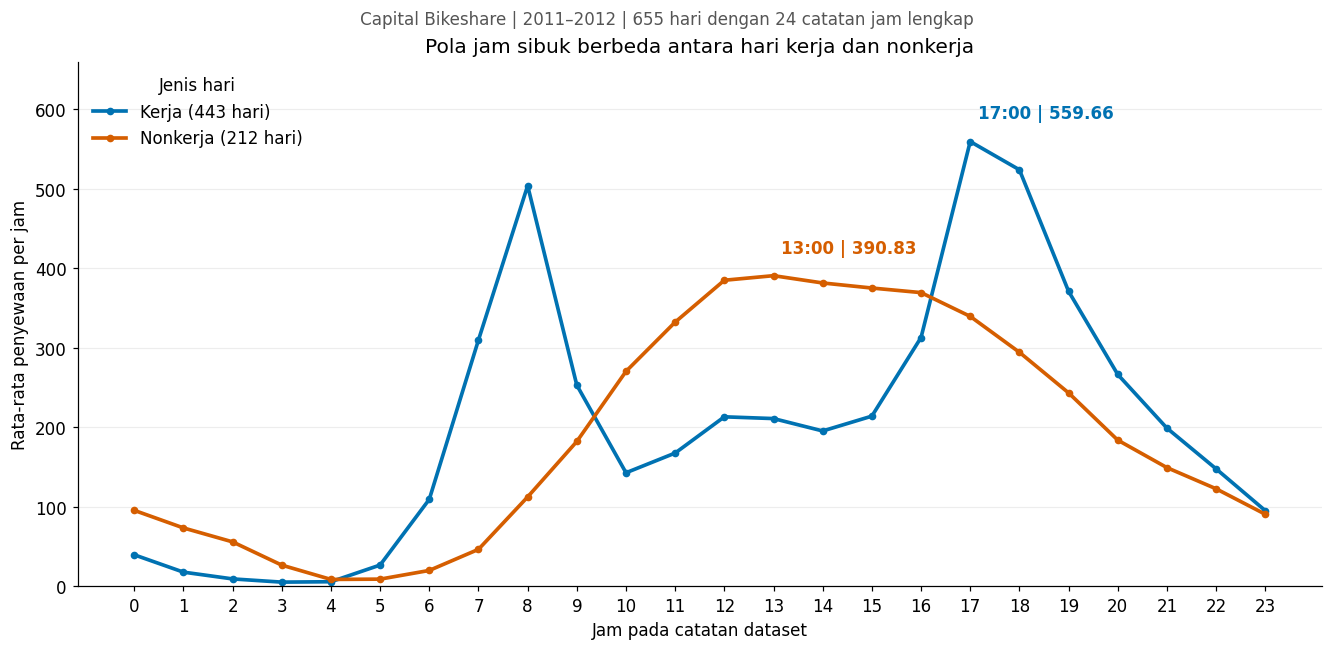

In [30]:
figures_dir = Path('outputs/figures')
figures_dir.mkdir(parents=True, exist_ok=True)
colors = {'Kerja': '#0072B2', 'Nonkerja': '#D55E00'}
fig, ax = plt.subplots(figsize=(12, 5.8), layout='constrained')
for day_type in ['Kerja', 'Nonkerja']:
    part = hourly_profile.loc[hourly_profile['day_type'].eq(day_type)].sort_values('hr')
    n_days = int(part['observed_hours'].iloc[0])
    ax.plot(part['hr'], part['mean_rentals'], marker='o', markersize=4,
            linewidth=2.4, color=colors[day_type], label=f'{day_type} ({n_days} hari)')
    peak = part.loc[part['mean_rentals'].idxmax()]
    ax.annotate(f"{int(peak['hr']):02d}:00 | {peak['mean_rentals']:.2f}",
                xy=(peak['hr'], peak['mean_rentals']), xytext=(5, 15),
                textcoords='offset points', color=colors[day_type], fontweight='bold')
ax.set(title='Pola jam sibuk berbeda antara hari kerja dan nonkerja',
       xlabel='Jam pada catatan dataset', ylabel='Rata-rata penyewaan per jam')
ax.set_xticks(range(24))
ax.set_ylim(0, hourly_profile['mean_rentals'].max() * 1.18)
ax.grid(axis='y', alpha=0.22)
ax.legend(title='Jenis hari', loc='upper left', frameon=False)
fig.suptitle('Capital Bikeshare | 2011–2012 | 655 hari dengan 24 catatan jam lengkap',
             fontsize=11, color='#555555')
fig.savefig(figures_dir / '01_pola_jam_sibuk.png', dpi=170, bbox_inches='tight')
plt.show()


### Pertanyaan 2: Bagaimana perubahan rata-rata harian per bulan pada 2012 dibanding 2011?


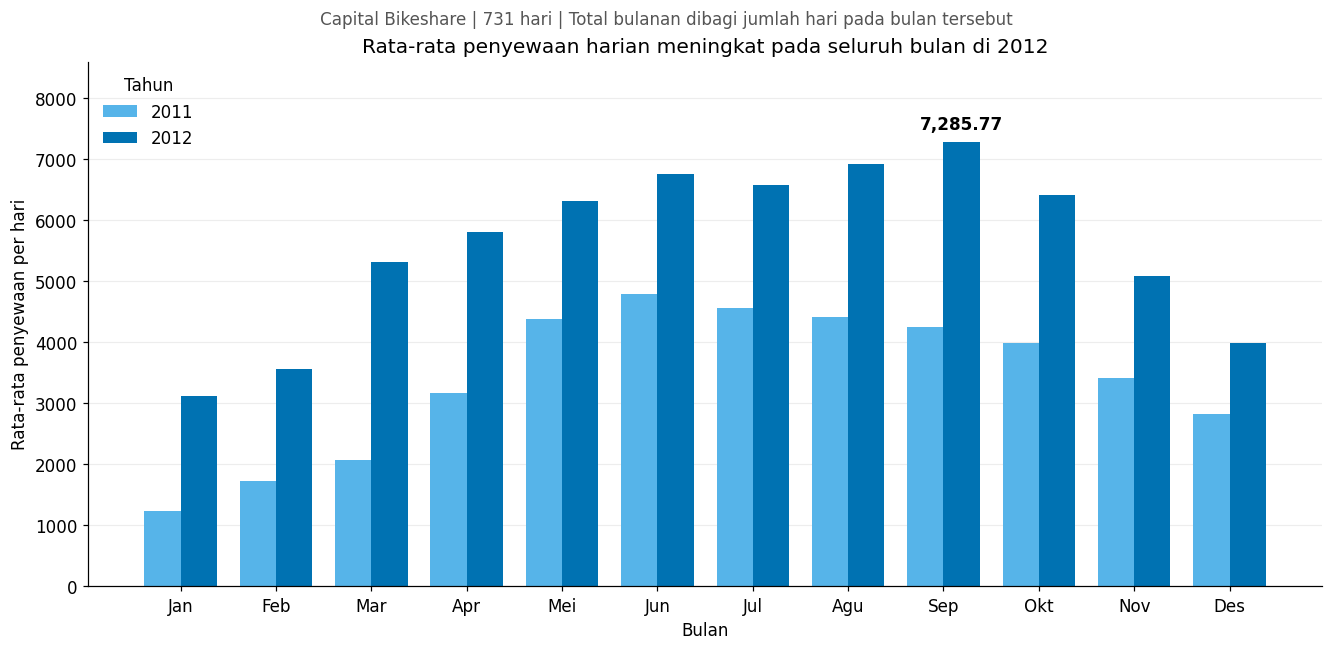

In [31]:
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
x = np.arange(12)
width = 0.38
fig, ax = plt.subplots(figsize=(12, 5.8), layout='constrained')
ax.bar(x - width/2, monthly_comparison['mean_2011'], width, color='#56B4E9', label='2011')
ax.bar(x + width/2, monthly_comparison['mean_2012'], width, color='#0072B2', label='2012')
ax.set(title='Rata-rata penyewaan harian meningkat pada seluruh bulan di 2012',
       xlabel='Bulan', ylabel='Rata-rata penyewaan per hari')
ax.set_xticks(x, month_names)
ax.set_ylim(0, monthly_comparison['mean_2012'].max() * 1.18)
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
ax.legend(title='Tahun', frameon=False, loc='upper left')
peak_month = int(monthly_comparison['mean_2012'].idxmax())
peak_value = monthly_comparison.loc[peak_month, 'mean_2012']
ax.annotate(f'{peak_value:,.2f}', xy=(peak_month - 1 + width/2, peak_value),
            xytext=(0, 8), textcoords='offset points', ha='center', fontweight='bold')
fig.suptitle('Capital Bikeshare | 731 hari | Total bulanan dibagi jumlah hari pada bulan tersebut',
             fontsize=11, color='#555555')
fig.savefig(figures_dir / '02_rerata_harian_bulanan.png', dpi=170, bbox_inches='tight')
plt.show()


**Insight dan interpretasi visualisasi:**
1. Grafik pertama menjawab pertanyaan 1: hari kerja mempunyai puncak pagi dan sore, sedangkan hari nonkerja terkonsentrasi sekitar tengah hari. Pola ini konsisten dengan perbedaan jadwal penggunaan, tetapi data agregat ini tidak membuktikan tujuan perjalanan pengguna.
2. Grafik kedua menjawab pertanyaan 2: pada semua bulan, rata-rata harian 2012 melampaui 2011. September memiliki permintaan rata-rata tertinggi pada 2012; pertumbuhan terbesar terjadi pada Maret, sebagaimana dihitung dalam tabel EDA.
3. Sumbu kuantitas dimulai dari nol, warna tahun/jenis hari konsisten, dan label mencantumkan periode, metrik, serta cakupan. Semua nilai grafik berasal dari tabel agregasi yang diekspor.


## Analisis Lanjutan (Opsional)

### Tujuan dan metode tahap 6

Analisis ini memperdalam dua pertanyaan bisnis melalui **manual grouping dan binning**, sesuai contoh analisis lanjutan pada ketentuan penilaian. Unit yang dikelompokkan adalah catatan waktu dan hari penyewaan.

**A. Pengelompokan waktu untuk pertanyaan 1.** Kolom `hr` dibagi dengan `pd.cut()` menjadi lima interval yang ditentukan secara eksplisit:

| Kelompok | Jam yang masuk | Lebar interval |
|---|---|---:|
| Dini hari | 00–05 | 6 jam |
| Pagi | 06–09 | 4 jam |
| Siang | 10–15 | 6 jam |
| Sore | 16–19 | 4 jam |
| Malam | 20–23 | 4 jam |

Interval tersebut merupakan pilihan analitis untuk merangkum pola waktu dan membantu perencanaan jadwal layanan. Batas waktu tidak diklaim sebagai jadwal resmi operator. Digunakan 655 hari dengan 24 catatan jam lengkap, konsisten dengan EDA. Rata-rata penyewaan **per jam** menjadi metrik perbandingan intensitas karena lebar interval berbeda. Pangsa volume dihitung terhadap total penyewaan pada jenis hari yang sama. Pangsa `registered` dihitung dari total kejadian sewa kategori tersebut dalam setiap kelompok.

**B. Binning tingkat penyewaan untuk pertanyaan 2.** Batas kategori dihitung dari kuartil 25% dan 75% jumlah penyewaan harian pada **2011**, lalu batas yang sama diterapkan pada 2011 dan 2012. Acuan tetap membuat perubahan komposisi antar-tahun dapat dibandingkan. Ini adalah kategori relatif terhadap distribusi 2011, bukan standar kapasitas operator.

Seluruh 731 tanggal dipakai dalam analisis harian. Jumlah hari per kategori dibagi jumlah hari pada tahun terkait, sehingga perbedaan 365 dan 366 hari diperhitungkan. Pemeriksaan sensitivitas memakai pasangan kuantil 20/80 dan 30/70, dengan acuan tetap 2011.

Implementasi menggunakan operasi pandas dan visualisasi Matplotlib. Referensi fungsi: [pandas.cut](https://pandas.pydata.org/docs/reference/api/pandas.cut.html) dan [Series.quantile](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html).


In [32]:
# A. Manual grouping: lima interval waktu yang tetap untuk kedua jenis hari.
# Gunakan subset hari lengkap yang sudah diverifikasi pada cleaning.
time_labels = ['Dini hari (00–05)', 'Pagi (06–09)', 'Siang (10–15)',
               'Sore (16–19)', 'Malam (20–23)']
time_edges = [0, 6, 10, 16, 20, 24]
hour_segmented = hour_analysis.copy()
hour_segmented['time_block'] = pd.cut(
    hour_segmented['hr'], bins=time_edges, labels=time_labels,
    right=False, ordered=True
)

time_block_summary = (
    hour_segmented.groupby(['day_type', 'time_block'], observed=True)
    .agg(observed_days=('dteday', 'nunique'), observed_hours=('cnt', 'size'),
         total_rentals=('cnt', 'sum'), mean_rentals_per_hour=('cnt', 'mean'),
         median_rentals_per_hour=('cnt', 'median'),
         casual_rentals=('casual', 'sum'), registered_rentals=('registered', 'sum'))
    .reset_index()
)
# Pangsa penyewaan memakai total penyewaan pada jenis hari yang sama.
time_block_summary['rental_share_pct'] = (
    time_block_summary['total_rentals']
    / time_block_summary.groupby('day_type', observed=True)['total_rentals'].transform('sum') * 100
)
# Pangsa registered adalah pangsa kejadian sewa, bukan jumlah orang unik.
time_block_summary['registered_share_pct'] = (
    time_block_summary['registered_rentals'] / time_block_summary['total_rentals'] * 100
)
display(time_block_summary.round(2))
print('Cakupan:', hour_segmented['dteday'].nunique(), 'hari lengkap dan',
      len(hour_segmented), 'catatan jam.')
print('Perbandingan intensitas memakai rata-rata per jam karena panjang interval berbeda.')


,day_type,time_block,observed_days,observed_hours,total_rentals,mean_rentals_per_hour,median_rentals_per_hour,casual_rentals,registered_rentals,rental_share_pct,registered_share_pct
0,Kerja,Dini hari (00–05),443,2658,45947,17.29,11.0,7619,38328,2.12,83.42
1,Kerja,Pagi (06–09),443,1772,521090,294.07,263.0,29967,491123,24.01,94.25
2,Kerja,Siang (10–15),443,2658,506770,190.66,184.0,116670,390100,23.35,76.98
3,Kerja,Sore (16–19),443,1772,783191,441.98,421.0,94473,688718,36.08,87.94
4,Kerja,Malam (20–23),443,1772,313744,177.06,161.0,42975,270769,14.45,86.30
5,Nonkerja,Dini hari (00–05),212,1272,56920,44.75,28.5,11137,45783,5.89,80.43
6,Nonkerja,Pagi (06–09),212,848,76466,90.17,58.0,17682,58784,7.91,76.88
7,Nonkerja,Siang (10–15),212,1272,452741,355.93,353.0,162181,290560,46.85,64.18
8,Nonkerja,Sore (16–19),212,848,264336,311.72,304.5,87270,177066,27.36,66.99
9,Nonkerja,Malam (20–23),212,848,115802,136.56,120.5,29309,86493,11.98,74.69


Cakupan: 655 hari lengkap dan 15720 catatan jam.
Perbandingan intensitas memakai rata-rata per jam karena panjang interval berbeda.


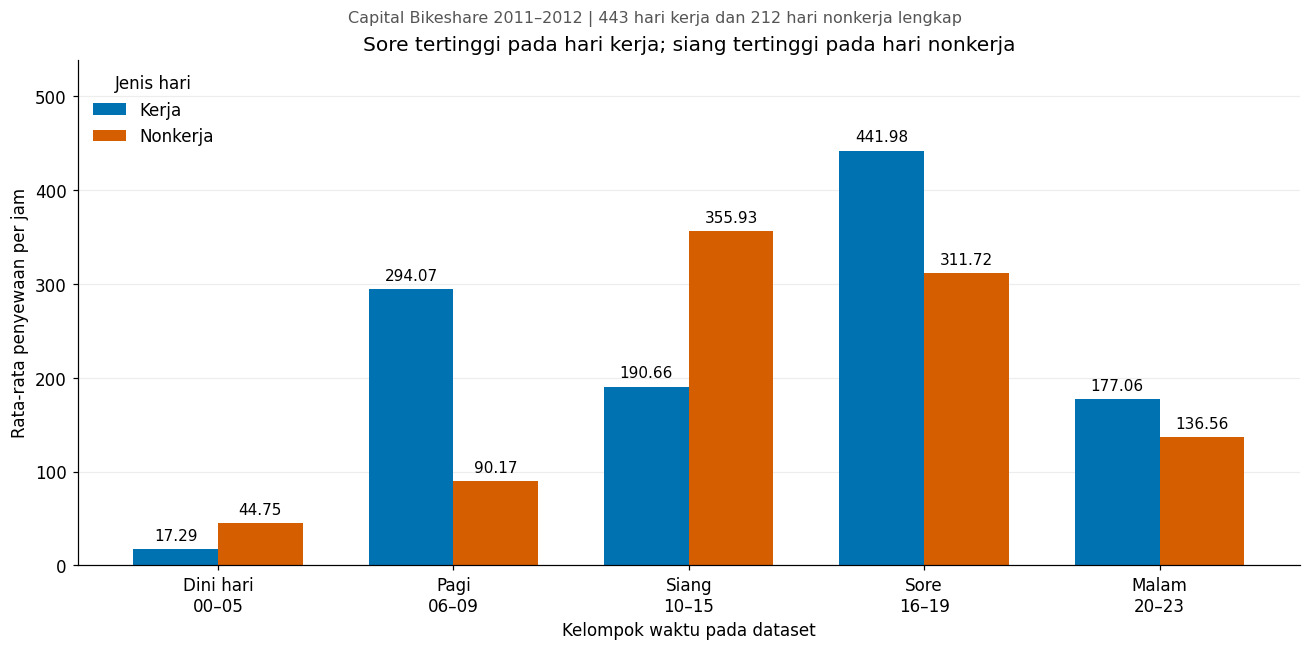

In [33]:
advanced_figures_dir = Path('outputs/figures')
advanced_figures_dir.mkdir(parents=True, exist_ok=True)
block_means = (time_block_summary.pivot(index='time_block', columns='day_type',
               values='mean_rentals_per_hour').reindex(time_labels))
x = np.arange(len(time_labels))
width = 0.36
fig, ax = plt.subplots(figsize=(11.8, 5.8), layout='constrained')
for offset, day_type, color in [(-width/2, 'Kerja', '#0072B2'),
                                (width/2, 'Nonkerja', '#D55E00')]:
    bars = ax.bar(x + offset, block_means[day_type], width,
                  color=color, label=day_type)
    ax.bar_label(bars, fmt='%.2f', padding=4, fontsize=10)
ax.set_xticks(x, ['Dini hari\n00–05', 'Pagi\n06–09', 'Siang\n10–15',
                 'Sore\n16–19', 'Malam\n20–23'])
ax.set(ylabel='Rata-rata penyewaan per jam', xlabel='Kelompok waktu pada dataset',
       title='Sore tertinggi pada hari kerja; siang tertinggi pada hari nonkerja',
       ylim=(0, block_means.max().max() * 1.22))
ax.grid(axis='y', alpha=0.22)
ax.set_axisbelow(True)
ax.legend(title='Jenis hari', frameon=False, loc='upper left')
fig.suptitle('Capital Bikeshare 2011–2012 | 443 hari kerja dan 212 hari nonkerja lengkap',
             fontsize=10.5, color='#555555')
fig.savefig(advanced_figures_dir / '03_time_block_demand.png', dpi=170, bbox_inches='tight')
plt.show()


### Interpretasi kelompok waktu

- **Hari kerja:** sore (16–19) mempunyai rata-rata tertinggi, **441,98 penyewaan per jam**, dan menyumbang **36,08%** volume penyewaan hari kerja dalam sampel hari lengkap. Pagi (06–09) berada pada **294,07 penyewaan per jam**; pangsa penyewaan kategori registered dalam kelompok pagi mencapai **94,25%**.
- **Hari nonkerja:** siang (10–15) mempunyai rata-rata tertinggi, **355,93 penyewaan per jam**, dan menyumbang **46,86%** volume penyewaan hari nonkerja dalam sampel yang sama.
- Hasil ini merangkum puncak jam individual pada EDA menjadi rentang waktu yang dapat digunakan untuk menyusun jadwal kesiapan layanan. Pangsa volume memperhitungkan seluruh jam dalam interval; interval enam jam memiliki paparan waktu lebih panjang daripada interval empat jam.
- `registered` menunjukkan kategori penyewaan. Data agregat ini tidak mengidentifikasi orang unik atau membuktikan tujuan perjalanan. Cakupan analisis tetap terbatas pada 655 hari lengkap.


In [34]:
# B. Binning tingkat penyewaan harian dengan satu acuan tetap: tahun 2011.
reference_counts = day_clean.loc[day_clean['year'].eq(2011), 'cnt']
q25, q75 = reference_counts.quantile([0.25, 0.75], interpolation='linear')
demand_labels = ['Rendah', 'Sedang', 'Tinggi']
day_segmented = day_clean.copy()
day_segmented['demand_level'] = pd.cut(
    day_segmented['cnt'], bins=[-np.inf, q25, q75, np.inf],
    labels=demand_labels, right=True, ordered=True
)
demand_thresholds = pd.DataFrame({
    'reference_year': [2011, 2011], 'quantile': [0.25, 0.75],
    'threshold_rentals_per_day': [q25, q75]
})
display(demand_thresholds)
print(f'Rendah: cnt <= {q25:,.0f}')
print(f'Sedang: {q25:,.0f} < cnt <= {q75:,.0f}')
print(f'Tinggi: cnt > {q75:,.0f}')

daily_demand_summary = (
    day_segmented.groupby(['year', 'demand_level'], observed=True)
    .agg(observed_days=('cnt', 'size'), mean_daily_rentals=('cnt', 'mean'),
         median_daily_rentals=('cnt', 'median'), min_rentals=('cnt', 'min'),
         max_rentals=('cnt', 'max'))
    .reset_index()
)
daily_demand_summary['day_share_pct'] = (
    daily_demand_summary['observed_days']
    / daily_demand_summary.groupby('year')['observed_days'].transform('sum') * 100
)
display(daily_demand_summary.round(2))
high_share = daily_demand_summary.loc[
    daily_demand_summary['demand_level'].eq('Tinggi')].set_index('year')['day_share_pct']
print('Perubahan proporsi hari tinggi (poin persentase):',
      round(high_share.loc[2012] - high_share.loc[2011], 2))


,reference_year,quantile,threshold_rentals_per_day
0,2011,0.25,2132.0
1,2011,0.75,4586.0


Rendah: cnt <= 2,132
Sedang: 2,132 < cnt <= 4,586
Tinggi: cnt > 4,586


,year,demand_level,observed_days,mean_daily_rentals,median_daily_rentals,min_rentals,max_rentals,day_share_pct
0,2011,Rendah,92,1473.80,1537.0,431,2132,25.21
1,2011,Sedang,182,3596.17,3742.0,2133,4586,49.86
2,2011,Tinggi,91,4978.13,4881.0,4590,6043,24.93
3,2012,Rendah,16,1368.62,1435.0,22,2114,4.37
4,2012,Sedang,86,3538.44,3610.5,2169,4585,23.50
5,2012,Tinggi,264,6527.92,6594.0,4639,8714,72.13


Perubahan proporsi hari tinggi (poin persentase): 47.2


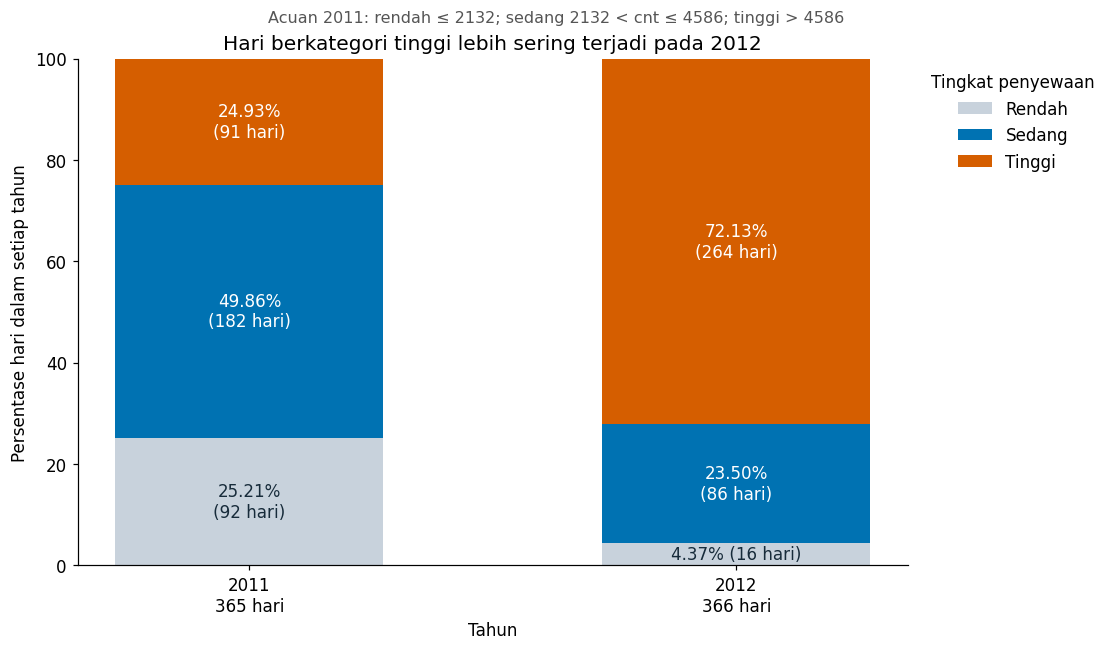

In [35]:
demand_pct = (daily_demand_summary.pivot(index='year', columns='demand_level',
              values='day_share_pct').reindex(columns=demand_labels))
demand_days = (daily_demand_summary.pivot(index='year', columns='demand_level',
               values='observed_days').reindex(columns=demand_labels))
fig, ax = plt.subplots(figsize=(10, 5.8), layout='constrained')
bottom = np.zeros(len(demand_pct))
for category, color, text_color in [('Rendah', '#C8D2DC', '#172B3A'),
                                    ('Sedang', '#0072B2', 'white'),
                                    ('Tinggi', '#D55E00', 'white')]:
    values = demand_pct[category].to_numpy()
    ax.bar(np.arange(len(demand_pct)), values, bottom=bottom, width=0.55,
           color=color, label=category)
    for position, year in enumerate(demand_pct.index):
        label = f'{values[position]:.2f}%'
        if values[position] >= 10:
            label += f'\n({int(demand_days.loc[year, category])} hari)'
        else:
            label += f' ({int(demand_days.loc[year, category])} hari)'
        ax.text(position, bottom[position] + values[position]/2, label,
                ha='center', va='center', color=text_color, fontsize=11)
    bottom += values
ax.set_xticks(np.arange(len(demand_pct)), ['2011\n365 hari', '2012\n366 hari'])
ax.set(ylim=(0, 100), ylabel='Persentase hari dalam setiap tahun', xlabel='Tahun',
       title='Hari berkategori tinggi lebih sering terjadi pada 2012')
ax.legend(title='Tingkat penyewaan', loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
fig.suptitle(f'Acuan 2011: rendah ≤ {q25:.0f}; sedang {q25:.0f} < cnt ≤ {q75:.0f}; tinggi > {q75:.0f}',
             fontsize=10.5, color='#555555')
fig.savefig(advanced_figures_dir / '04_daily_demand_levels.png', dpi=170, bbox_inches='tight')
plt.show()


### Interpretasi tingkat penyewaan harian

Batas kuartil acuan 2011 adalah **Q25 = 2.132** dan **Q75 = 4.586** penyewaan per hari:

| Kategori | Aturan jumlah penyewaan per hari |
|---|---|
| Rendah | `cnt <= 2132` |
| Sedang | `2132 < cnt <= 4586` |
| Tinggi | `cnt > 4586` |

- Pada 2011 terdapat **91 dari 365 hari (24,93%)** berkategori tinggi. Pada 2012 terdapat **264 dari 366 hari (72,13%)**.
- Proporsi hari tinggi meningkat **47,20 poin persentase**. Poin persentase adalah selisih dua persentase, bukan persentase pertumbuhan relatif.
- Rata-rata penyewaan dalam kategori tinggi adalah **4.978,13** pada 2011 dan **6.527,92** pada 2012. Kategori tetap memakai satu batas yang sama; masing-masing kelompok dapat mempunyai rata-rata berbeda.
- Pergeseran kategori mendukung temuan pertumbuhan bulanan pada EDA. Hasil ini menunjukkan lebih seringnya hari dengan penyewaan melampaui ambang 2011; tidak mengukur kekurangan armada atau penyebab pertumbuhan.


In [36]:
# C. Sensitivitas: geser pasangan kuantil, selalu memakai tahun acuan 2011.
sensitivity_rows = []
for lower_q, upper_q in [(0.20, 0.80), (0.25, 0.75), (0.30, 0.70)]:
    lower_value, upper_value = reference_counts.quantile([lower_q, upper_q])
    high_pct = (day_clean.assign(is_high=day_clean['cnt'].gt(upper_value))
                .groupby('year')['is_high'].mean() * 100)
    sensitivity_rows.append({
        'lower_quantile': lower_q, 'upper_quantile': upper_q,
        'lower_threshold': lower_value, 'upper_threshold': upper_value,
        'high_day_pct_2011': high_pct.loc[2011], 'high_day_pct_2012': high_pct.loc[2012],
        'change_percentage_points': high_pct.loc[2012] - high_pct.loc[2011]
    })
demand_sensitivity = pd.DataFrame(sensitivity_rows)
display(demand_sensitivity.round(2))

advanced_validation = pd.DataFrame([
    ('Semua jam analisis mendapat kelompok waktu', hour_segmented['time_block'].notna().all()),
    ('Jumlah jam dan total sewa per jam tetap', len(hour_segmented) == len(hour_analysis)
     and hour_segmented['cnt'].sum() == hour_analysis['cnt'].sum()),
    ('Semua hari mendapat tingkat penyewaan', day_segmented['demand_level'].notna().all()),
    ('Jumlah hari dan total sewa harian tetap', len(day_segmented) == len(day_clean)
     and day_segmented['cnt'].sum() == day_clean['cnt'].sum()),
    ('Pangsa periode berjumlah 100% per jenis hari',
     np.allclose(time_block_summary.groupby('day_type', observed=True)['rental_share_pct'].sum(), 100)),
    ('Pangsa kategori berjumlah 100% per tahun',
     np.allclose(daily_demand_summary.groupby('year')['day_share_pct'].sum(), 100)),
    ('Sampel acuan hanya memakai 2011', len(reference_counts) == day_clean['year'].eq(2011).sum()),
], columns=['pemeriksaan', 'lulus'])
display(advanced_validation)
assert advanced_validation['lulus'].all(), 'Periksa hasil pengelompokan sebelum melanjutkan.'

# Simpan berkas tahap 6. Dataframe dan ekspor tahap 1–5 tetap tersedia.
advanced_dir = Path('outputs/advanced')
advanced_dir.mkdir(parents=True, exist_ok=True)
Path('data/processed').mkdir(parents=True, exist_ok=True)
time_block_summary.to_csv(advanced_dir / 'time_block_summary.csv', index=False)
daily_demand_summary.to_csv(advanced_dir / 'daily_demand_summary.csv', index=False)
demand_thresholds.to_csv(advanced_dir / 'demand_thresholds.csv', index=False)
demand_sensitivity.to_csv(advanced_dir / 'demand_sensitivity.csv', index=False)
advanced_validation.to_csv(advanced_dir / 'advanced_validation.csv', index=False)
hour_segmented[['dteday', 'hr', 'day_type', 'time_block', 'casual', 'registered', 'cnt']].to_csv(
    'data/processed/hour_segmented.csv', index=False)
day_segmented[['dteday', 'year', 'month', 'cnt', 'demand_level']].to_csv(
    'data/processed/day_segmented.csv', index=False)

# ZIP ini hanya memudahkan pengunduhan hasil tahap 6 dari Colab.
from zipfile import ZipFile, ZIP_DEFLATED
stage6_paths = list(advanced_dir.glob('*.csv')) + [
    Path('data/processed/hour_segmented.csv'), Path('data/processed/day_segmented.csv'),
    Path('outputs/figures/03_time_block_demand.png'),
    Path('outputs/figures/04_daily_demand_levels.png')
]
with ZipFile('hasil_tahap6.zip', 'w', ZIP_DEFLATED) as archive:
    for path in sorted(stage6_paths):
        archive.write(path, arcname=path.as_posix())
print('Selesai. Unduh hasil_tahap6.zip dari Files dan notebook dari menu File.')


,lower_quantile,upper_quantile,lower_threshold,upper_threshold,high_day_pct_2011,high_day_pct_2012,change_percentage_points
0,0.20,0.80,1870.6,4696.8,20.00,71.04,51.04
1,0.25,0.75,2132.0,4586.0,24.93,72.13,47.20
2,0.30,0.70,2435.8,4447.4,30.14,74.32,44.18


,pemeriksaan,lulus
0,Semua jam analisis mendapat kelompok waktu,True
1,Jumlah jam dan total sewa per jam tetap,True
2,Semua hari mendapat tingkat penyewaan,True
3,Jumlah hari dan total sewa harian tetap,True
4,Pangsa periode berjumlah 100% per jenis hari,True
5,Pangsa kategori berjumlah 100% per tahun,True
6,Sampel acuan hanya memakai 2011,True


Selesai. Unduh hasil_tahap6.zip dari Files dan notebook dari menu File.


### Pemeriksaan sensitivitas, validasi, dan batas interpretasi

- Dengan batas atas kuantil 80% (4.696,8), proporsi hari tinggi berubah dari **20,00%** menjadi **71,04%**.
- Dengan batas atas kuantil 70% (4.447,4), proporsi berubah dari **30,14%** menjadi **74,32%**.
- Pada ketiga skenario, proporsi hari tinggi tetap lebih besar pada 2012. Arah kesimpulan stabil terhadap pergeseran ambang yang diperiksa. Pemeriksaan ini bukan uji signifikansi statistik atau pembuktian bahwa satu ambang merupakan batas terbaik.
- Seluruh pemeriksaan integritas harus bernilai **True**: kategori terisi, baris dan total penyewaan dipertahankan, serta persentase berjumlah 100% untuk kelompok acuannya.
- Batas kuartil tidak dihitung ulang secara terpisah pada 2012. Menghitung kuartil tiap tahun secara terpisah akan mengubah definisi kategori dan menyamarkan pergeseran terhadap acuan yang sama.
- Data tahun 2011–2012 menggambarkan kondisi historis. Penerapan pada operasional sekarang memerlukan data terbaru dan informasi kapasitas layanan.


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada hari lengkap selama 2011–2012, prioritas jam sibuk hari kerja adalah 17:00, 18:00, dan 08:00, dengan rata-rata 559,66; 524,11; dan 504,05 penyewaan per jam. Pada hari nonkerja, prioritasnya 13:00, 12:00, dan 14:00, dengan rata-rata 390,83; 385,07; dan 381,65. Peringkat tersebut tetap sama pada pemeriksaan seluruh jam yang tersedia.
- **Conclusion pertanyaan 2:** Seluruh bulan tahun 2012 memiliki rata-rata penyewaan harian yang lebih tinggi daripada bulan yang sama pada 2011. Maret mencatat pertumbuhan tertinggi (+157,44%, atau +3.252,58 penyewaan per hari), sedangkan September 2012 memiliki tingkat permintaan rata-rata tertinggi (7.285,77 penyewaan per hari).

**Batas interpretasi:** Hasil mewakili data historis Capital Bikeshare 2011–2012. Seleksi hari lengkap mengecualikan 76 tanggal dari analisis utama per jam; penyebab gap tidak diketahui. Analisis deskriptif ini tidak mengisolasi sebab pertumbuhan, belum menunjukkan ketersediaan armada, dan tidak dapat menentukan kebutuhan stok tiap stasiun.
**Kesimpulan tambahan analisis lanjutan:** Pengelompokan waktu menempatkan sore hari kerja dan siang hari nonkerja sebagai interval dengan intensitas penyewaan tertinggi. Binning dengan acuan tetap 2011 menunjukkan proporsi hari tinggi meningkat dari 24,93% menjadi 72,13%, dan arah perubahannya konsisten pada dua skenario ambang pembanding.


**Rekomendasi Action Item:**
- Untuk simulasi perencanaan berdasarkan periode dataset, uji penyesuaian jadwal kesiapan layanan menjelang pukul 08:00 dan 17:00–18:00 pada hari kerja, serta 12:00–14:00 pada hari nonkerja. Penetapan jumlah armada membutuhkan data ketersediaan, durasi sewa, dan lokasi yang belum tersedia di tabel ini.
- Gunakan tingkat permintaan September dan lonjakan pertumbuhan Maret sebagai dua masukan terpisah untuk perencanaan kapasitas musiman; evaluasi kembali dengan data periode terbaru sebelum penerapan operasional saat ini.
- Perbaiki pemeriksaan kelengkapan pencatatan per jam dan verifikasi sumber kelembapan pada 2011-03-10 sebelum melakukan analisis lingkungan lanjutan.
- Gunakan rentang 16–19 pada hari kerja dan 10–15 pada hari nonkerja sebagai prioritas evaluasi kesiapan layanan, sambil mempertahankan rincian jam puncak dari EDA untuk menentukan waktu persiapan.
- Gunakan bertambahnya proporsi hari di atas 4.586 penyewaan sebagai dasar untuk meninjau ulang asumsi perencanaan yang hanya mengacu pada 2011. Besarnya penambahan armada membutuhkan data kapasitas dan permintaan tidak terlayani.

**Status:** Tahap 1–6 telah terisi dan dijalankan pada versi ini. Pembuatan dashboard Streamlit, pengujian lokal, deployment, dan audit submission akhir menjadi tahap berikutnya.
